# 1A pilot — Diacritic noise vs. accuracy on Vietnamese sentiment

> **Tóm tắt (VI):** Notebook thử nghiệm đầu tiên cho ý tưởng 1A. Tạo các phiên bản "nhiễu" (bỏ dấu một phần, bỏ dấu hết, teen code) của bộ UIT-VSFC, đo thống kê tokenizer của 6 mô hình, đo độ chính xác phân loại cảm xúc, rồi xem thống kê nào dự đoán được mức sụt giảm.

**What this notebook does**

1. Builds a noise suite: `clean`, `partial25/50/75` (strip diacritics from 25/50/75% of the syllables that have them), `strip` (all), `teencode`.
2. Tokenizer statistics per model × condition: fertility, broken-syllable rate, byte-fragment rate.
3. Zero-shot sentiment accuracy (label scoring, no generation) and NLL per syllable for each model × condition.
4. Analysis: accuracy drop with bootstrap CIs, and Spearman correlation between the drop and each tokenizer statistic.

**Runtime:** `Runtime → Change runtime type → L4 GPU` (≈3 CU/h). The full pilot takes about 30–45 min, so roughly 2–3 CU. T4 also works, just slower.

**Results** go to Google Drive (`MyDrive/llm-research/1A-pilot/`). If Colab disconnects, run all cells again: models that are already finished are skipped.

⚠️ When you are done: `Runtime → Disconnect and delete runtime`, otherwise CU keeps draining.

## 0. Setup

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install -U transformers accelerate

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/llm-research/1A-pilot"
else:
    OUT_DIR = "outputs/1A-pilot"
os.makedirs(f"{OUT_DIR}/preds", exist_ok=True)
print("Saving results to", OUT_DIR)

Mounted at /content/drive
Saving results to /content/drive/MyDrive/llm-research/1A-pilot


In [3]:
# Only needed for gated models (Gemma, Llama). In Colab: 🔑 Secrets panel → add HF_TOKEN,
# and accept each model's licence on its Hugging Face page first.
HF_TOKEN = None
if IN_COLAB:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        print("No HF_TOKEN secret — gated models will be skipped.")

No HF_TOKEN secret — gated models will be skipped.


In [4]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(p.name, f"{p.total_memory / 1e9:.1f} GB")
    # T4 (compute capability 7.5) has no real bfloat16, so it gets float16
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    print("⚠️ No GPU. Runtime → Change runtime type → L4 GPU")
    DTYPE = torch.float32
print("dtype:", DTYPE)

NVIDIA L4 23.7 GB
dtype: torch.bfloat16


## 1. Config

Use the newest small version of each family when you start the real study. Models with no chat template (bloomz) get a plain "Nhãn:" prompt.

In [5]:
MODELS = [
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen3-1.7B",
    "SeaLLMs/SeaLLMs-v3-1.5B-Chat",      # Southeast-Asian
    "vilm/vinallama-2.7b-chat",          # Vietnamese (Llama-2 based)
    "HuggingFaceTB/SmolLM2-1.7B-Instruct",  # mostly English: a low-exposure contrast
    "bigscience/bloomz-1b7",             # multilingual, no chat template
]
GATED_MODELS = ["google/gemma-3-1b-it", "meta-llama/Llama-3.2-1B-Instruct"]
if HF_TOKEN:
    MODELS += GATED_MODELS

CONDITIONS = ["clean", "partial25", "partial50", "partial75", "strip", "teencode"]
N_PER_CLASS = 100   # balanced sample: 100 negative, 100 neutral, 100 positive
SEED = 42
BATCH_SIZE = 16

## 2. Noise generator

- **Partial removal** strips an exact share of the syllables *that carry diacritics* (syllables like "anh" have nothing to strip).
- **Teen code** is a small rule table. ✏️ Check it yourself and extend it — your notes say this table must be checked by a native speaker (you).
- Noise is applied only to the student's sentence, never to the instruction or the labels.

In [6]:
import random, re, unicodedata

def strip_diacritics(s):
    s = s.replace("đ", "d").replace("Đ", "D")
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", s)

def partial_strip(text, rate, rng):
    words = text.split(" ")
    candidates = [i for i, w in enumerate(words) if strip_diacritics(w) != w]
    chosen = set(rng.sample(candidates, round(rate * len(candidates))))
    return " ".join(strip_diacritics(w) if i in chosen else w for i, w in enumerate(words))

TEENCODE = {
    "giáo viên": "gv", "sinh viên": "sv",
    "không": "ko", "được": "dc", "gì": "j", "với": "vs", "mình": "mk", "rồi": "r",
    "vậy": "v", "bạn": "bn", "quá": "wa", "nhiều": "nhìu", "người": "ng", "trước": "trc",
    "cũng": "cx", "thôi": "thui", "biết": "bít", "yêu": "iu", "giờ": "h",
}
_teen_re = re.compile(
    r"(?<!\w)(" + "|".join(sorted(map(re.escape, TEENCODE), key=len, reverse=True)) + r")(?!\w)",
    re.IGNORECASE,
)

def teencode(text):
    return _teen_re.sub(lambda m: TEENCODE[m.group(0).lower()], text)

def make_noisy(text, cond, item_id):
    rng = random.Random(f"{SEED}-{item_id}-{cond}")  # same noise every run
    if cond == "clean":
        return text
    if cond == "strip":
        return strip_diacritics(text)
    if cond.startswith("partial"):
        return partial_strip(text, int(cond[len("partial"):]) / 100, rng)
    if cond == "teencode":
        return teencode(text)
    raise ValueError(cond)

# sanity checks
assert strip_diacritics("Tôi muốn đặt vé máy bay") == "Toi muon dat ve may bay"
assert teencode("giáo viên không nói gì") == "gv ko nói j"
s = "thầy dạy rất nhiệt tình và dễ hiểu"
for c in CONDITIONS:
    print(f"{c:10} {make_noisy(s, c, 0)}")

clean      thầy dạy rất nhiệt tình và dễ hiểu
partial25  thay dạy rất nhiet tình và dễ hiểu
partial50  thay dạy rat nhiet tình và de hiểu
partial75  thầy day rat nhiet tinh va dễ hieu
strip      thay day rat nhiet tinh va de hieu
teencode   thầy dạy rất nhiệt tình và dễ hiểu


## 3. Data: UIT-VSFC (students' feedback sentiment), test split

In [7]:
import pandas as pd

URL = ("https://huggingface.co/datasets/uitnlp/vietnamese_students_feedback/resolve/"
       "refs%2Fconvert%2Fparquet/default/test/0000.parquet")
raw = pd.read_parquet(URL)
print(len(raw), "test rows; class counts:", raw.sentiment.value_counts().sort_index().to_dict())

sample = raw.groupby("sentiment").sample(n=N_PER_CLASS, random_state=SEED).reset_index(drop=True)
sample["item_id"] = range(len(sample))

rows = [{"item_id": r.item_id, "label": r.sentiment, "cond": c, "clean": r.sentence,
         "text": make_noisy(r.sentence, c, r.item_id)}
        for r in sample.itertuples() for c in CONDITIONS]
data = pd.DataFrame(rows)
data.to_csv(f"{OUT_DIR}/noisy_items.csv", index=False)

changed = (data.text != data.clean).groupby(data.cond).mean()
print("share of items changed by each condition:\n", changed.round(2).to_string())
data[data.item_id == 0][["cond", "text"]]

3166 test rows; class counts: {0: 1409, 1: 167, 2: 1590}
share of items changed by each condition:
 cond
clean        0.00
partial25    0.94
partial50    0.97
partial75    1.00
strip        1.00
teencode     0.54


,cond,text
0,clean,giáo viên giảng dạy khá nhanh .
1,partial25,giáo viên giảng dạy kha nhanh .
2,partial50,giáo vien giảng dạy kha nhanh .
3,partial75,giao viên giang day kha nhanh .
4,strip,giao vien giang day kha nhanh .
5,teencode,gv giảng dạy khá nhanh .


## 4. Tokenizer statistics (CPU, ~1 min)

- **fertility** = tokens ÷ syllables of the *clean* sentence (same denominator for every condition, so teen code abbreviations do not look "cheaper").
- **broken_rate** = share of syllables split into more than one token.
- **fragment_rate** = share of tokens that are not a whole character on their own (byte pieces, e.g. half of "ộ").

In [8]:
from transformers import AutoTokenizer
from tqdm.auto import tqdm

def syllable_spans(text):
    return [(m.start(), m.end()) for m in re.finditer(r"\S+", text) if any(ch.isalpha() for ch in m.group())]

def tokenizer_stats(tok, df):
    n_tok = n_clean_syl = n_syl = n_broken = n_frag = 0
    for text, clean in zip(df.text, df.clean):
        enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
        ids, offs = enc["input_ids"], enc["offset_mapping"]
        spans = syllable_spans(text)
        n_tok += len(ids)
        n_clean_syl += len(syllable_spans(clean))
        n_syl += len(spans)
        n_broken += sum(sum(1 for s, e in offs if e > a and s < b and e > s) > 1 for a, b in spans)
        n_frag += sum("�" in tok.decode([i]) for i in ids)
    return {"fertility": n_tok / n_clean_syl, "broken_rate": n_broken / n_syl, "fragment_rate": n_frag / n_tok}

tok_rows = []
for name in tqdm(MODELS):
    tok = AutoTokenizer.from_pretrained(name, token=HF_TOKEN)
    for cond, g in data.groupby("cond"):
        tok_rows.append({"model": name, "cond": cond, **tokenizer_stats(tok, g)})
tok_stats = pd.DataFrame(tok_rows)
tok_stats.to_csv(f"{OUT_DIR}/tokenizer_stats.csv", index=False)
tok_stats.pivot(index="model", columns="cond", values="fertility")[CONDITIONS].round(2)

  0%|          | 0/6 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/222 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 14.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

cond,clean,partial25,partial50,partial75,strip,teencode
model,,,,,,
HuggingFaceTB/SmolLM2-1.7B-Instruct,3.54,3.11,2.68,2.26,1.81,3.33
Qwen/Qwen2.5-1.5B-Instruct,1.29,1.37,1.45,1.53,1.60,1.29
Qwen/Qwen3-1.7B,1.29,1.37,1.45,1.53,1.60,1.29
SeaLLMs/SeaLLMs-v3-1.5B-Chat,1.29,1.37,1.45,1.53,1.60,1.29
bigscience/bloomz-1b7,1.18,1.24,1.30,1.35,1.41,1.17
vilm/vinallama-2.7b-chat,1.17,1.24,1.30,1.37,1.43,1.18


## 5. Model evaluation (GPU)

For each item we score the three labels ("tiêu cực", "trung tính", "tích cực") by their log-probability after the prompt and pick the highest. No generation, so no answer parsing. Both casings count ("tiêu cực" and "Tiêu cực"), because chat models usually start the answer with a capital.

Small models often prefer one label whatever the input (Qwen2.5-0.5B answers "Tiêu cực" to everything). So we also report **calibrated** predictions (contextual calibration, [Zhao et al. 2021](https://arxiv.org/abs/2102.09690)): measure the label preference on content-free inputs ("", "N/A") and subtract it. `pred` is calibrated, `pred_raw` is not; report both in the paper.

We also measure **NLL per clean syllable** of the sentence itself (how "surprised" the model is by the noisy text).

Each finished model is saved to `preds/`, so a disconnect only loses the model in progress.

In [9]:
import gc, time
import torch.nn.functional as F
from transformers import AutoModelForCausalLM

LABELS = ["tiêu cực", "trung tính", "tích cực"]  # 0 negative, 1 neutral, 2 positive
INSTRUCTION = ("Phân loại cảm xúc của câu nhận xét sau của sinh viên. "
               "Trả lời bằng đúng một nhãn: tiêu cực, trung tính, hoặc tích cực.\n\nCâu: {text}")
NLL_CONTEXT = "Nhận xét của sinh viên:"

def prompt_ids(tok, text):
    msg = INSTRUCTION.format(text=text)
    if tok.chat_template:
        # enable_thinking=False only matters for Qwen3; other templates ignore it
        s = tok.apply_chat_template([{"role": "user", "content": msg}], tokenize=False,
                                    add_generation_prompt=True, enable_thinking=False)
        return tok(s, add_special_tokens=False)["input_ids"]
    return tok(msg + "\nNhãn:", add_special_tokens=True)["input_ids"]

def label_ids(tok):
    # per label: [lowercase, Capitalised] token ids
    prefix = "" if tok.chat_template else " "
    return [[tok(prefix + v, add_special_tokens=False)["input_ids"] for v in (l, l.capitalize())] for l in LABELS]

def nll_ids(tok, text):
    # score only the sentence, after a short clean context (Qwen has no BOS token to start from)
    s = f"{NLL_CONTEXT} {text}"
    enc = tok(s, add_special_tokens=True, return_offsets_mapping=True)
    first = next(i for i, (a, b) in enumerate(enc["offset_mapping"]) if b > a and a >= len(NLL_CONTEXT))
    return enc["input_ids"], first

@torch.no_grad()
def score(model, pad_id, seqs, starts):
    # seqs[i][starts[i]:] is the scored part; returns (sum log-prob, n scored tokens) per sequence
    L = max(map(len, seqs))
    ids = torch.full((len(seqs), L), pad_id)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
        mask[i, :len(s)] = 1
    ids, mask = ids.to(model.device), mask.to(model.device)
    logits = model(input_ids=ids, attention_mask=mask).logits
    pick = torch.zeros_like(mask, dtype=torch.bool)  # pick[i, t]: logits at t predict token t+1
    for i, (s, st) in enumerate(zip(seqs, starts)):
        pick[i, st - 1:len(s) - 1] = True
    lp = F.log_softmax(logits[pick].float(), dim=-1)
    tgt = ids[:, 1:][pick[:, :-1]]
    tok_lp = lp.gather(1, tgt[:, None]).squeeze(1)
    owner = pick.nonzero()[:, 0]
    sums = torch.zeros(len(seqs), device=lp.device).index_add_(0, owner, tok_lp)
    counts = pick.sum(1)
    return sums.cpu().tolist(), counts.cpu().tolist()

def batched(xs, n):
    for i in range(0, len(xs), n):
        yield xs[i:i + n]

def evaluate(name):
    tok = AutoTokenizer.from_pretrained(name, token=HF_TOKEN)
    model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE, token=HF_TOKEN).to(DEVICE).eval()
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else (tok.eos_token_id or 0)
    lab = label_ids(tok)

    def label_logprobs(texts, desc):
        # (n_texts, 3) log-probs; each label sums its two casings
        seqs, starts = [], []
        for text in texts:
            p = prompt_ids(tok, text)
            for variants in lab:
                for v in variants:
                    seqs.append(p + v)
                    starts.append(len(p))
        lps = []
        for chunk in tqdm(list(batched(list(zip(seqs, starts)), BATCH_SIZE)), desc=desc, leave=False):
            lps += score(model, pad_id, *zip(*chunk))[0]
        return torch.tensor(lps).view(len(texts), 3, 2).logsumexp(-1)

    lp = label_logprobs(list(data.text), "labels")
    # contextual calibration: average label distribution on content-free inputs
    prior = label_logprobs(["", "N/A"], "prior").log_softmax(-1).exp().mean(0).log()

    # sentence NLL: 1 sequence per item
    nll_seqs = [nll_ids(tok, t) for t in data.text]
    nll, ntok = [], []
    for chunk in tqdm(list(batched(nll_seqs, BATCH_SIZE)), desc="nll", leave=False):
        s, c = score(model, pad_id, *zip(*chunk))
        nll += [-x for x in s]
        ntok += c

    out = data[["item_id", "label", "cond"]].copy()
    out["model"] = name
    for k in range(3):
        out[f"lp{k}"] = lp[:, k].tolist()
    out["pred_raw"] = lp.argmax(1).tolist()
    out["pred"] = (lp.log_softmax(-1) - prior).argmax(1).tolist()
    out["nll"] = nll
    out["nll_tokens"] = ntok
    out["clean_syl"] = [len(syllable_spans(c)) for c in data.clean]
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return out

for name in MODELS:
    path = f"{OUT_DIR}/preds/{name.replace('/', '__')}.csv"
    if os.path.exists(path):
        print("✓ already done:", name)
        continue
    t0 = time.time()
    res = evaluate(name)
    res.to_csv(path, index=False)
    acc = (res.pred == res.label).groupby(res.cond).mean()
    raw = (res.pred_raw == res.label).groupby(res.cond).mean()
    print(f"✓ {name} ({time.time() - t0:.0f}s)  clean={acc['clean']:.2f} (raw {raw['clean']:.2f})  "
          f"strip={acc['strip']:.2f} (raw {raw['strip']:.2f})")

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

labels:   0%|          | 0/675 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

labels:   0%|          | 0/675 [00:00<?, ?it/s]

prior:   0%|          | 0/1 [00:00<?, ?it/s]

nll:   0%|          | 0/113 [00:00<?, ?it/s]

✓ bigscience/bloomz-1b7 (84s)  clean=0.44 (raw 0.40)  strip=0.38 (raw 0.36)


## 6. Analysis

- **drop** = clean accuracy − noisy accuracy, with a 95% paired bootstrap CI (resampling items).
- **ppl_ratio** = exp(NLL per syllable on noisy − on clean). Above 1 = the model finds the noisy text more surprising.
- A predictor shows `NaN` when it never changes (e.g. a tokenizer with no byte fragments at all).
- Spearman correlation across all (model × noisy condition) points. With ~6 models × 5 conditions this is a *pilot*: read it as a direction, not a result.

In [10]:
import numpy as np
from sklearn.metrics import f1_score
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings("ignore", message="An input array is constant")

preds = pd.concat([pd.read_csv(f"{OUT_DIR}/preds/{m.replace('/', '__')}.csv") for m in MODELS
                   if os.path.exists(f"{OUT_DIR}/preds/{m.replace('/', '__')}.csv")])
preds["correct"] = (preds.pred == preds.label).astype(int)
preds["correct_raw"] = (preds.pred_raw == preds.label).astype(int)

rng = np.random.default_rng(SEED)
rows = []
for m, gm in preds.groupby("model"):
    clean = gm[gm.cond == "clean"].set_index("item_id")
    nll_clean = clean.nll.sum() / clean.clean_syl.sum()
    for c in CONDITIONS:
        g = gm[gm.cond == c].set_index("item_id").loc[clean.index]
        diff = (clean.correct - g.correct).values
        boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(1000)]
        rows.append({
            "model": m, "cond": c,
            "acc": g.correct.mean(), "acc_raw": g.correct_raw.mean(),
            "macro_f1": f1_score(g.label, g.pred, average="macro"),
            "drop": diff.mean(), "drop_lo": np.percentile(boot, 2.5), "drop_hi": np.percentile(boot, 97.5),
            "ppl_ratio": np.exp(g.nll.sum() / g.clean_syl.sum() - nll_clean),
        })
summary = pd.DataFrame(rows).merge(tok_stats, on=["model", "cond"])
clean_tok = summary[summary.cond == "clean"].set_index("model")
for k in ["fertility", "broken_rate", "fragment_rate"]:
    summary[f"d_{k}"] = summary[k] - summary.model.map(clean_tok[k])
summary.to_csv(f"{OUT_DIR}/summary.csv", index=False)

summary.pivot(index="model", columns="cond", values="acc")[CONDITIONS].round(3)

cond,clean,partial25,partial50,partial75,strip,teencode
model,,,,,,
HuggingFaceTB/SmolLM2-1.7B-Instruct,0.340,0.323,0.347,0.363,0.363,0.343
Qwen/Qwen2.5-1.5B-Instruct,0.717,0.603,0.493,0.433,0.353,0.693
Qwen/Qwen3-1.7B,0.337,0.333,0.337,0.337,0.337,0.337
SeaLLMs/SeaLLMs-v3-1.5B-Chat,0.357,0.333,0.323,0.337,0.323,0.357
bigscience/bloomz-1b7,0.443,0.397,0.363,0.387,0.377,0.450
vilm/vinallama-2.7b-chat,0.627,0.580,0.530,0.503,0.410,0.653


In [11]:
noisy = summary[summary.cond != "clean"]
corr = pd.DataFrame([
    {"predictor": k, "spearman_rho": spearmanr(noisy[k], noisy["drop"])[0], "p": spearmanr(noisy[k], noisy["drop"])[1]}
    for k in ["d_fertility", "d_broken_rate", "d_fragment_rate", "ppl_ratio"]
])
print(f"{len(noisy)} (model × noisy condition) points")
corr.round(3)

30 (model × noisy condition) points


,predictor,spearman_rho,p
0,d_fertility,0.622,0.000
1,d_broken_rate,0.609,0.000
2,d_fragment_rate,0.517,0.003
3,ppl_ratio,0.638,0.000


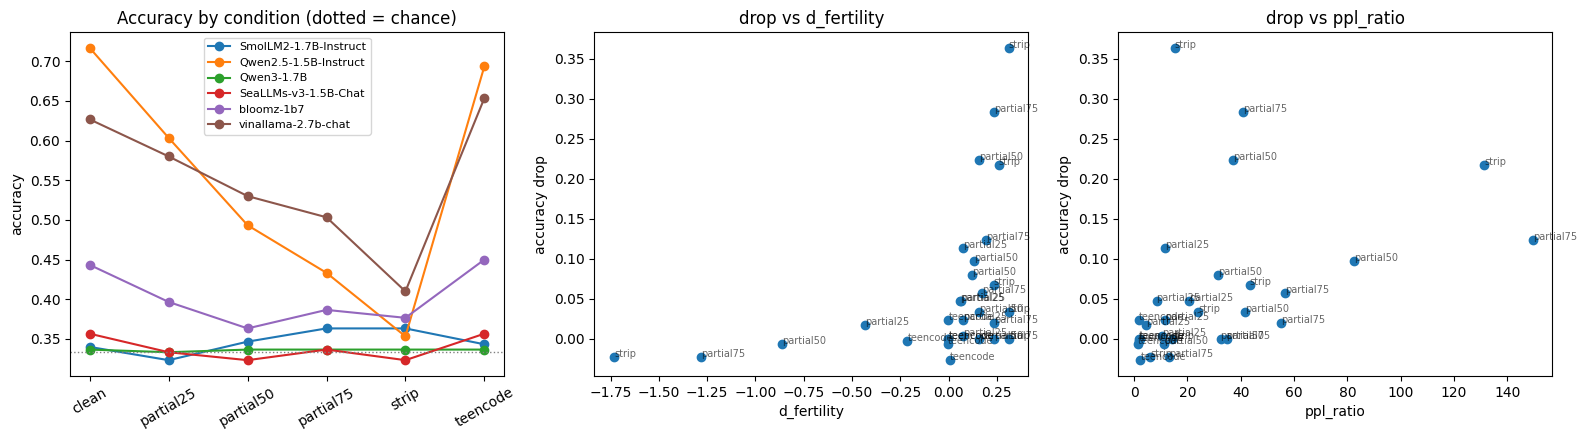

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for m, g in summary.groupby("model"):
    g = g.set_index("cond").loc[CONDITIONS]
    axes[0].plot(CONDITIONS, g.acc, marker="o", label=m.split("/")[1])
axes[0].axhline(1 / 3, color="gray", ls=":", lw=1)
axes[0].set(title="Accuracy by condition (dotted = chance)", ylabel="accuracy")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
for ax, k in zip(axes[1:], ["d_fertility", "ppl_ratio"]):
    ax.scatter(noisy[k], noisy["drop"])
    for r in noisy.itertuples():
        ax.annotate(r.cond, (getattr(r, k), r.drop), fontsize=7, alpha=0.6)
    ax.set(title=f"drop vs {k}", xlabel=k, ylabel="accuracy drop")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/pilot_plots.png", dpi=150)
plt.show()

## 7. What to write in your paper note

1. Which model is most robust to `strip`? Is it the one with the smallest fertility change?
2. Does accuracy fall smoothly with partial25 → 50 → 75 → strip, or is there a cliff?
3. Which correlates better with the drop: `d_fertility` (tokenizer) or `ppl_ratio` (model exposure)? That is the core question of 1A.
4. Look at 20 items that are correct when clean and wrong when stripped (code below). What kinds of words broke?

Then: `Runtime → Disconnect and delete runtime`.

In [13]:
m = MODELS[0]
p = preds[preds.model == m].pivot(index="item_id", columns="cond", values="correct")
flipped = p[(p.clean == 1) & (p.strip == 0)].index[:20]
data[(data.item_id.isin(flipped)) & (data.cond.isin(["clean", "strip"]))].pivot(index="item_id", columns="cond", values="text")

cond,clean,strip
item_id,,
26,thêm bài tập minh họa trong thực hành .,them bai tap minh hoa trong thuc hanh .
104,mặc dù có kiến thức tốt !,mac du co kien thuc tot !
105,thầy dạy ổn ạ .,thay day on a .
108,có kết hợp với bài tập ví dụ .,co ket hop voi bai tap vi du .
109,môn công nghệ web và ứng dụng có 2 tín chỉ lý ...,mon cong nghe web va ung dung co 2 tin chi ly ...
112,bài tập và hướng dẫn giải bài tập trên lớp .,bai tap va huong dan giai bai tap tren lop .
116,khi chia nhóm em không học bên nhóm của thầy n...,khi chia nhom em khong hoc ben nhom cua thay n...
117,cũng được .,cung duoc .
120,nói chung là không có vấn đề tiêu cực với phươ...,noi chung la khong co van de tieu cuc voi phuo...
